# DATA LOADING

In [1]:
import pandas as pd
test = pd.read_csv("ecommerce_orders_transactions_2026.csv")
test.head()

,Order_ID,Order_Date,Order_Time,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Customer_Country,Customer_Continent,Customer_City,...,Review_Sentiment,Is_Repeat_Customer,Sales_Region,Warehouse,Supplier,Order_Profit_USD,Profit_Margin_Percentage,Is_Bestseller_Product,Is_New_Customer,Is_First_Order
0,ORD-105927,2026-02-10,11:34:55,CUST-000001,Mateo Park,65,Male,Canada,North America,Vancouver,...,Neutral,False,North America,Frankfurt,Asia Consumer Goods Ltd,-51.34,-46.73,False,False,True
1,ORD-178205,2026-02-19,10:10:49,CUST-000001,Mateo Park,65,Male,Canada,North America,Vancouver,...,Negative,True,North America,London,International Retail Distribution,24.30,16.34,False,False,False
2,ORD-057651,2026-07-19,11:44:02,CUST-000002,Nina Wong,23,Female,New Zealand,Oceania,Auckland,...,Neutral,False,Asia Pacific,Toronto,Premium Electronics Supply,64.77,25.86,False,False,True
3,ORD-124661,2026-08-26,18:13:21,CUST-000003,Aisha Moore,19,Female,Kenya,Africa,Eldoret,...,Positive,False,Africa,Dubai,Premium Electronics Supply,9.29,12.57,False,False,True
4,ORD-162453,2026-09-08,10:34:46,CUST-000003,Aisha Moore,19,Female,Kenya,Africa,Eldoret,...,Neutral,True,Africa,Toronto,Global Home Supplies,-15.16,-13.75,False,False,False


In [2]:
train = pd.read_csv("ecommerce_orders_transactions_2026.csv")
train.head()

,Order_ID,Order_Date,Order_Time,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Customer_Country,Customer_Continent,Customer_City,...,Review_Sentiment,Is_Repeat_Customer,Sales_Region,Warehouse,Supplier,Order_Profit_USD,Profit_Margin_Percentage,Is_Bestseller_Product,Is_New_Customer,Is_First_Order
0,ORD-105927,2026-02-10,11:34:55,CUST-000001,Mateo Park,65,Male,Canada,North America,Vancouver,...,Neutral,False,North America,Frankfurt,Asia Consumer Goods Ltd,-51.34,-46.73,False,False,True
1,ORD-178205,2026-02-19,10:10:49,CUST-000001,Mateo Park,65,Male,Canada,North America,Vancouver,...,Negative,True,North America,London,International Retail Distribution,24.30,16.34,False,False,False
2,ORD-057651,2026-07-19,11:44:02,CUST-000002,Nina Wong,23,Female,New Zealand,Oceania,Auckland,...,Neutral,False,Asia Pacific,Toronto,Premium Electronics Supply,64.77,25.86,False,False,True
3,ORD-124661,2026-08-26,18:13:21,CUST-000003,Aisha Moore,19,Female,Kenya,Africa,Eldoret,...,Positive,False,Africa,Dubai,Premium Electronics Supply,9.29,12.57,False,False,True
4,ORD-162453,2026-09-08,10:34:46,CUST-000003,Aisha Moore,19,Female,Kenya,Africa,Eldoret,...,Neutral,True,Africa,Toronto,Global Home Supplies,-15.16,-13.75,False,False,False


# Data Cleaning dan Transformation

# Mengidentifikasi Informasi Dataset

In [3]:
# Menampilkan ringkasan informasi dari dataset
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Order_ID                  200000 non-null  object 
 1   Order_Date                200000 non-null  object 
 2   Order_Time                200000 non-null  object 
 3   Customer_ID               200000 non-null  object 
 4   Customer_Name             200000 non-null  object 
 5   Customer_Age              200000 non-null  int64  
 6   Customer_Gender           200000 non-null  object 
 7   Customer_Country          200000 non-null  object 
 8   Customer_Continent        200000 non-null  object 
 9   Customer_City             200000 non-null  object 
 10  Customer_Region           200000 non-null  object 
 11  Customer_Segment          200000 non-null  object 
 12  Product_ID                200000 non-null  object 
 13  SKU                       200000 non-null  o

In [4]:
# Menampilkan statistik deskriptif dari dataset
train.describe(include="all")

,Order_ID,Order_Date,Order_Time,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Customer_Country,Customer_Continent,Customer_City,...,Review_Sentiment,Is_Repeat_Customer,Sales_Region,Warehouse,Supplier,Order_Profit_USD,Profit_Margin_Percentage,Is_Bestseller_Product,Is_New_Customer,Is_First_Order
count,200000,200000,200000,200000,200000,200000.000000,200000,200000,200000,200000,...,200000,200000,200000,200000,200000,200000.000000,200000.000000,200000,200000,200000
unique,200000,352,67367,69728,69728,NaN,4,51,6,208,...,3,2,5,12,9,NaN,NaN,2,2,2
top,ORD-105927,2026-11-06,09:55:36,CUST-017913,Carlos Robinson 17912,NaN,Male,Czech Republic,Europe,Doha,...,Positive,True,Asia Pacific,London,Urban Fashion Wholesale,NaN,NaN,False,False,False
freq,1,822,17,12,12,NaN,95955,4203,74381,3914,...,108448,130272,77895,16883,22488,NaN,NaN,170689,193188,130272
mean,NaN,NaN,NaN,NaN,NaN,46.468095,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,152.470468,10.045555,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,16.744957,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,328.661830,47.494389,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,18.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,-1325.470000,-1445.040000,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,32.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,1.270000,1.620000,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,46.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,33.350000,19.530000,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,61.000000,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,147.362500,33.710000,NaN,NaN,NaN


In [5]:
# Memeriksa jumlah nilai yang hilang di setiap kolom
missing_values = train.isnull().sum()
missing_values[missing_values > 0]

Return_Reason    191670
Coupon_Code      170165
dtype: int64

# Mengatasi Missing Value

In [6]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

In [7]:
# Contoh mengisi nilai yang hilang dengan median untuk kolom numerik
numeric_features = train[less].select_dtypes(include=['number']).columns
train[numeric_features] = train[numeric_features].fillna(train[numeric_features].median())

In [8]:
# Contoh mengisi nilai yang hilang dengan mode untuk kolom kategori
categorical_features = train[less].select_dtypes(include=['object']).columns

for column in categorical_features:
    train[column] = train[column].fillna(train[column].mode()[0])

In [9]:
# Menghapus kolom dengan terlalu banyak nilai yang hilang
df = train.drop(columns=over)

In [10]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

# Mengatasi Outliers

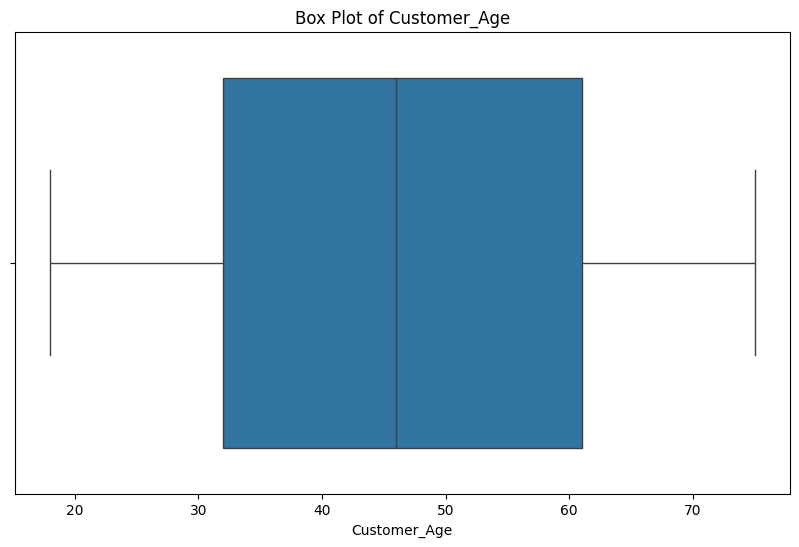

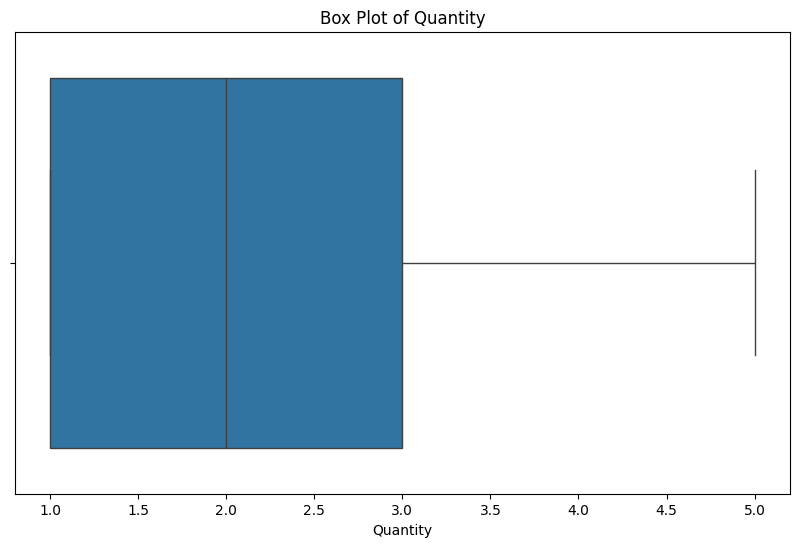

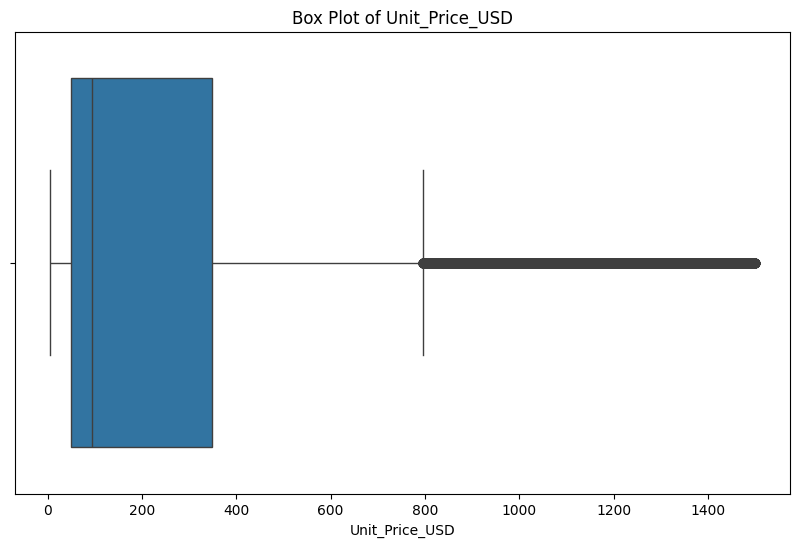

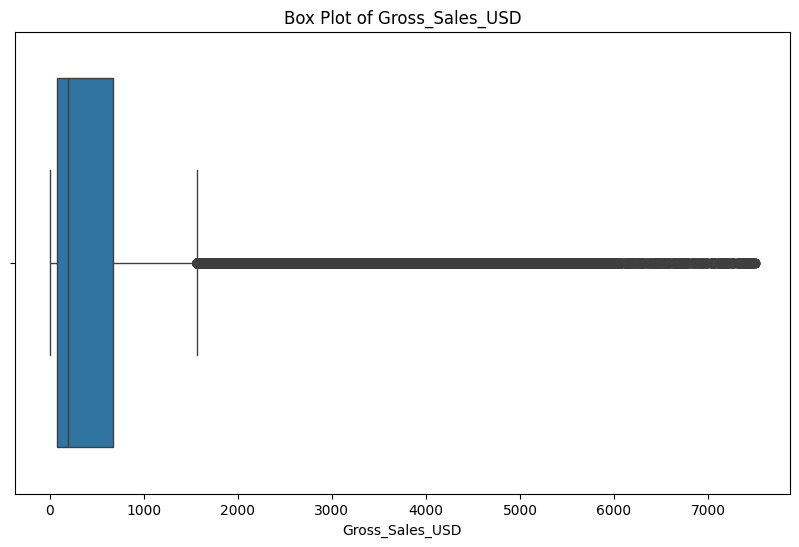

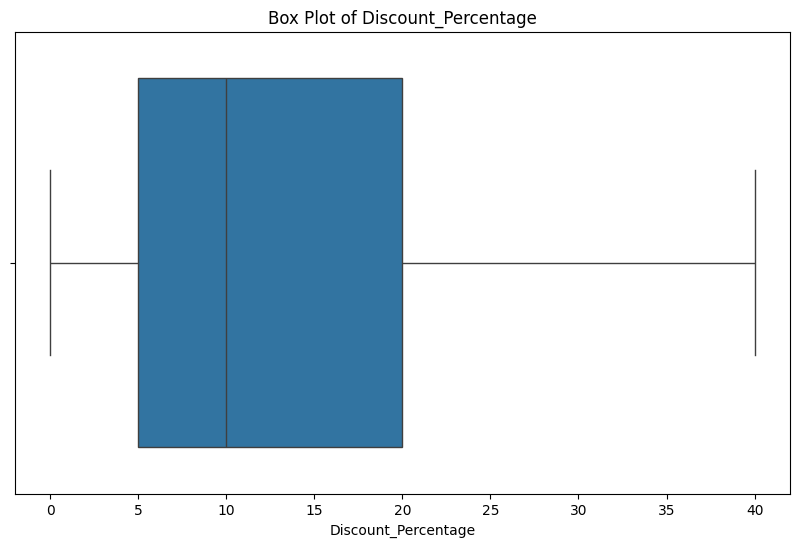

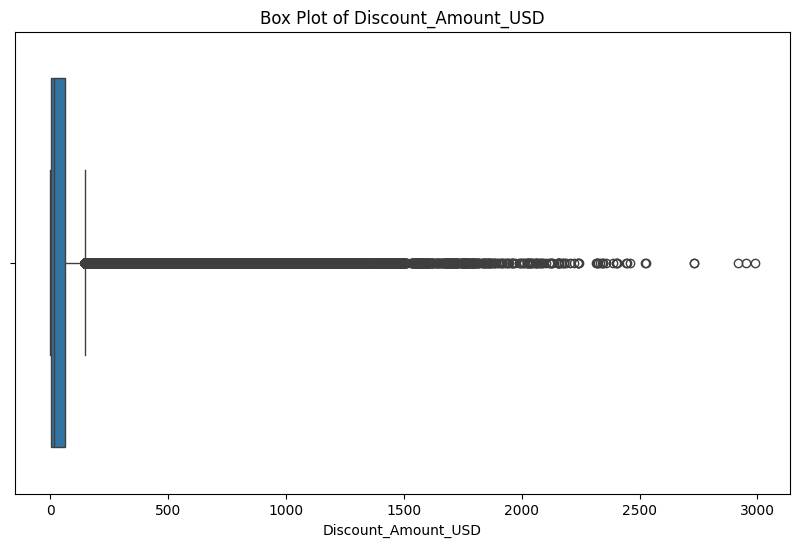

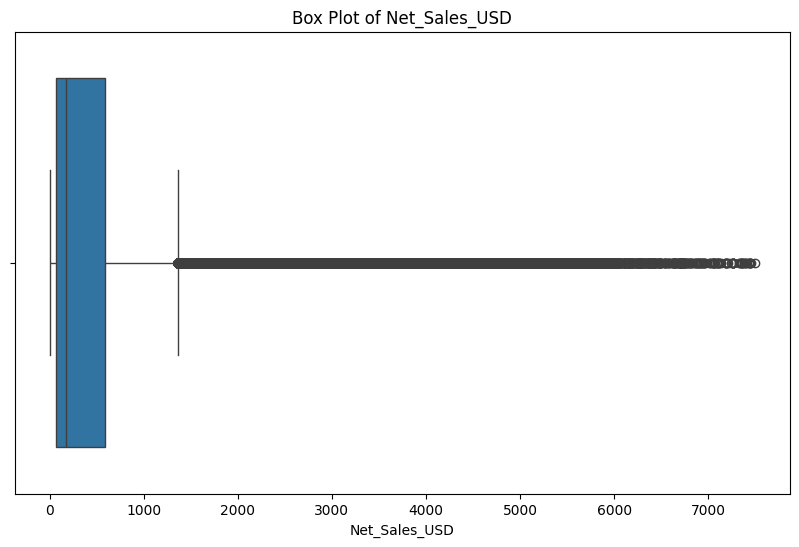

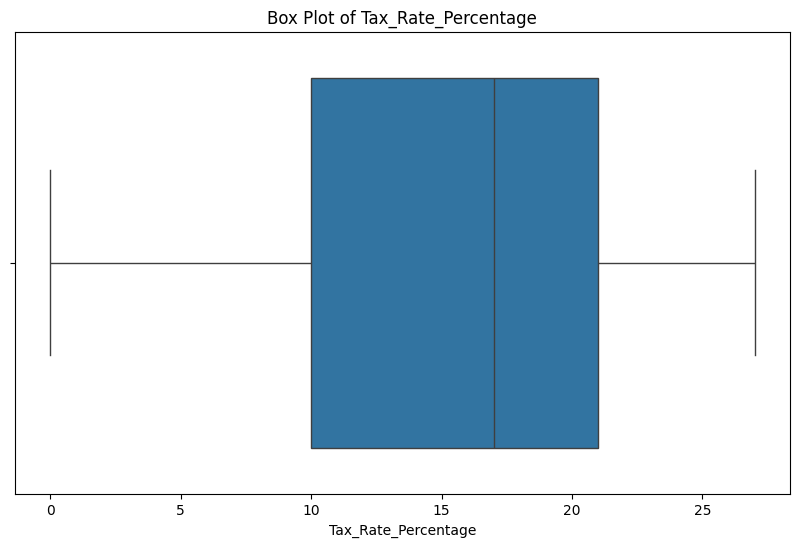

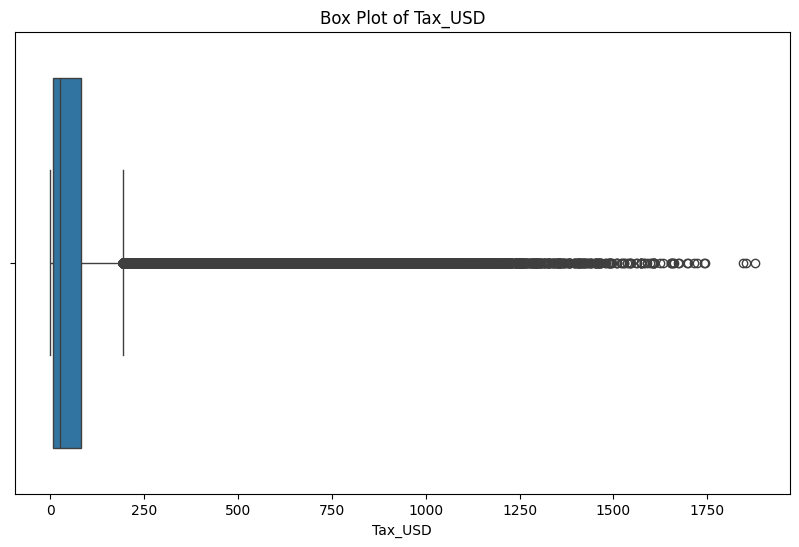

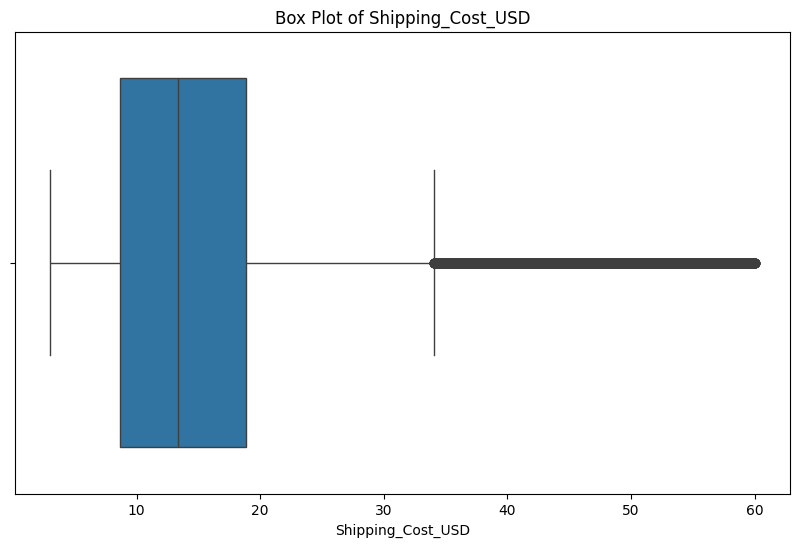

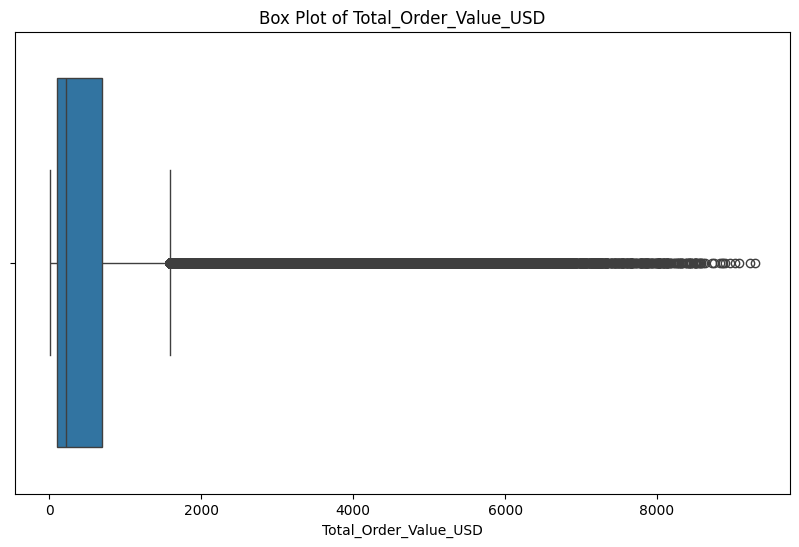

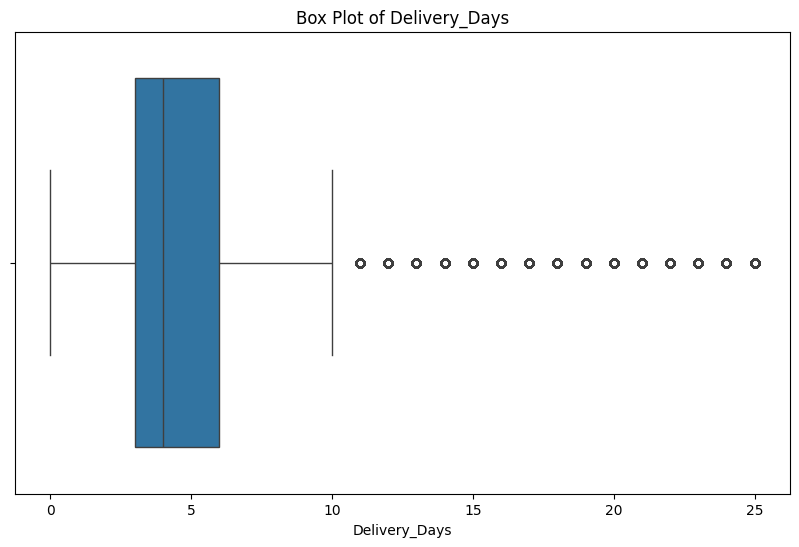

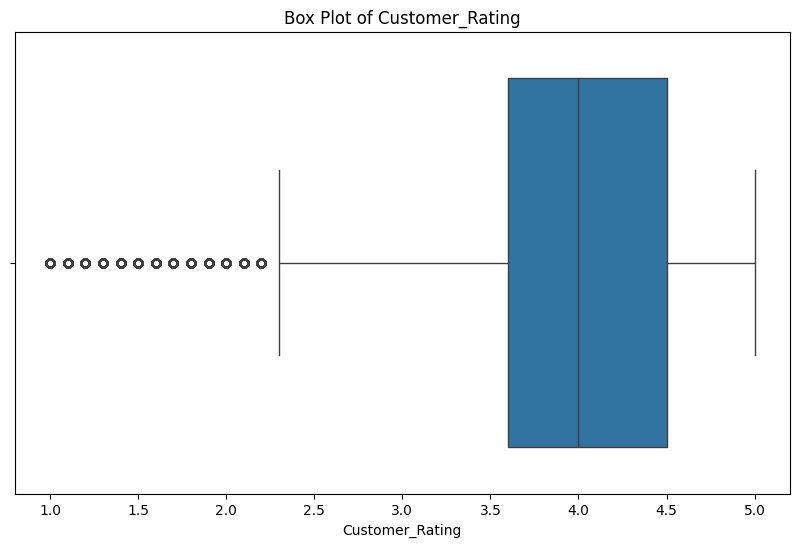

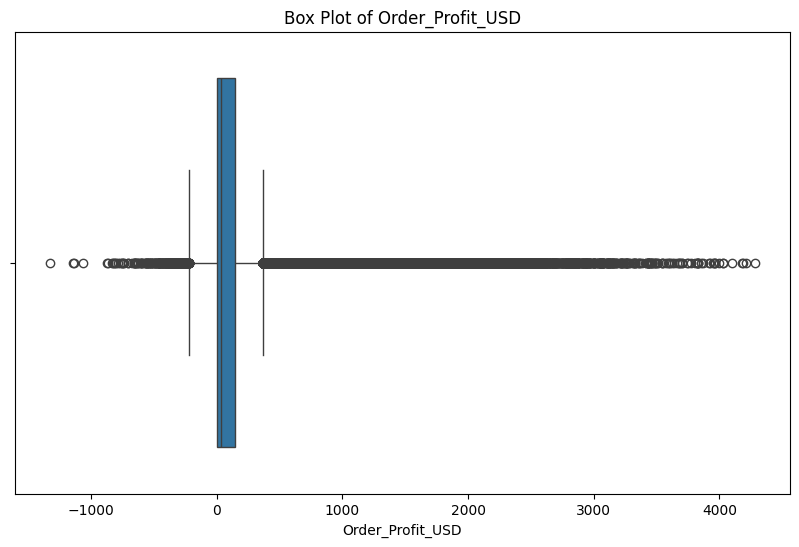

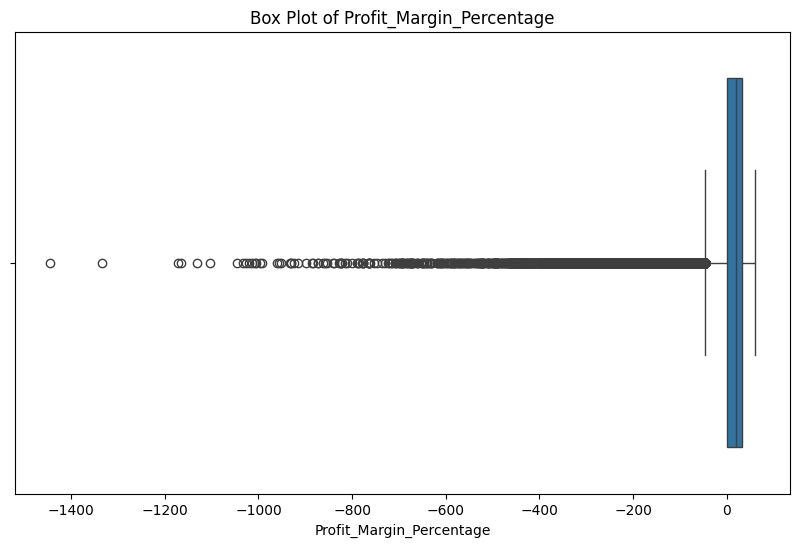

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

In [12]:
# Contoh sederhana untuk mengidentifikasi outliers menggunakan IQR
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)
IQR = Q3 - Q1

In [13]:
# Filter dataframe untuk menghapus baris yang mengandung outlier

condition = ~(
    (df[numeric_features] < (Q1 - 1.5 * IQR)) |
    (df[numeric_features] > (Q3 + 1.5 * IQR))
).any(axis=1)

df_filtered_numeric = df.loc[condition, numeric_features]

# Menggabungkan kembali dengan kolom kategorikal
categorical_features = df.select_dtypes(include=['object']).columns

df = pd.concat(
    [df_filtered_numeric, df.loc[condition, categorical_features]],
    axis=1
)

print("Jumlah data sebelum dan sesudah filtering:")
print("Jumlah data setelah filtering:", len(df))
display(df.head())

Jumlah data sebelum dan sesudah filtering:
Jumlah data setelah filtering: 124933


,Customer_Age,Quantity,Unit_Price_USD,Gross_Sales_USD,Discount_Percentage,Discount_Amount_USD,Net_Sales_USD,Tax_Rate_Percentage,Tax_USD,Shipping_Cost_USD,...,Payment_Status,Order_Status,Shipping_Method,Return_Status,Marketing_Channel,Device_Type,Review_Sentiment,Sales_Region,Warehouse,Supplier
1,65,1,160.81,160.81,7.5,12.06,148.75,10.0,14.88,16.44,...,Paid,Processing,Express,No Return,Email Marketing,Desktop,Negative,North America,London,International Retail Distribution
2,23,1,278.34,278.34,10.0,27.83,250.51,15.0,37.58,9.27,...,Paid,Delivered,Standard,No Return,Social Media,Tablet,Neutral,Asia Pacific,Toronto,Premium Electronics Supply
3,19,1,86.94,86.94,15.0,13.04,73.90,16.0,11.82,8.14,...,Paid,Delivered,Economy,No Return,Social Media,Tablet,Positive,Africa,Dubai,Premium Electronics Supply
4,19,2,73.50,147.00,25.0,36.75,110.25,16.0,17.64,22.21,...,Pending,Processing,Express,No Return,Organic Search,Desktop,Neutral,Africa,Toronto,Global Home Supplies
5,19,2,461.39,922.78,10.0,92.28,830.50,16.0,132.88,7.92,...,Pending,Delivered,Economy,No Return,Paid Search,Tablet,Positive,Africa,Hong Kong,Global Home Supplies


In [14]:
# Mengatasi outlier dengan mengganti nilai menggunakan median

for column in numeric_features:
    Q1_col = df[column].quantile(0.25)
    Q3_col = df[column].quantile(0.75)
    IQR_col = Q3_col - Q1_col
    median = df[column].median()

    lower_bound = Q1_col - 1.5 * IQR_col
    upper_bound = Q3_col + 1.5 * IQR_col

    df[column] = df[column].apply(
        lambda x: median if x < lower_bound or x > upper_bound else x
    )

print("Outlier berhasil ditangani dengan median.")
display(df.head())

Outlier berhasil ditangani dengan median.


,Customer_Age,Quantity,Unit_Price_USD,Gross_Sales_USD,Discount_Percentage,Discount_Amount_USD,Net_Sales_USD,Tax_Rate_Percentage,Tax_USD,Shipping_Cost_USD,...,Payment_Status,Order_Status,Shipping_Method,Return_Status,Marketing_Channel,Device_Type,Review_Sentiment,Sales_Region,Warehouse,Supplier
1,65,1,160.81,160.81,7.5,12.06,148.75,10.0,14.88,16.44,...,Paid,Processing,Express,No Return,Email Marketing,Desktop,Negative,North America,London,International Retail Distribution
2,23,1,278.34,278.34,10.0,27.83,250.51,15.0,37.58,9.27,...,Paid,Delivered,Standard,No Return,Social Media,Tablet,Neutral,Asia Pacific,Toronto,Premium Electronics Supply
3,19,1,86.94,86.94,15.0,13.04,73.90,16.0,11.82,8.14,...,Paid,Delivered,Economy,No Return,Social Media,Tablet,Positive,Africa,Dubai,Premium Electronics Supply
4,19,2,73.50,147.00,25.0,36.75,110.25,16.0,17.64,22.21,...,Pending,Processing,Express,No Return,Organic Search,Desktop,Neutral,Africa,Toronto,Global Home Supplies
5,19,2,79.07,150.54,10.0,11.95,130.41,16.0,18.07,7.92,...,Pending,Delivered,Economy,No Return,Paid Search,Tablet,Positive,Africa,Hong Kong,Global Home Supplies


# Normalisasi dan Standardisasi Data

In [15]:
from sklearn.preprocessing import StandardScaler

# Standardisasi fitur numerik
scaler = StandardScaler()
df[numeric_features] = scaler.fit_transform(df[numeric_features])

Text(0.5, 1.0, 'Histogram Sebelum Standardisasi')

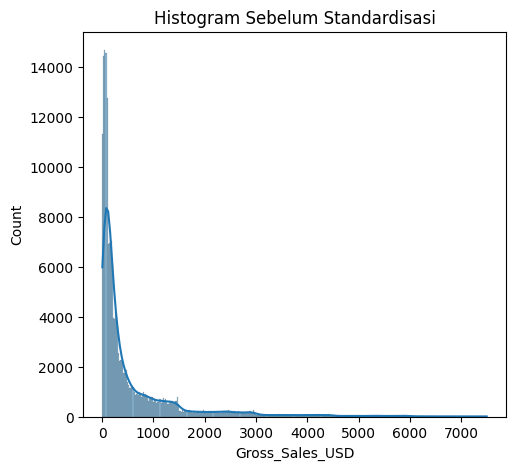

In [16]:
# Histogram Sebelum Standardisasi
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.histplot(train[numeric_features[3]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

Text(0.5, 1.0, 'Histogram Setelah Standardisasi')

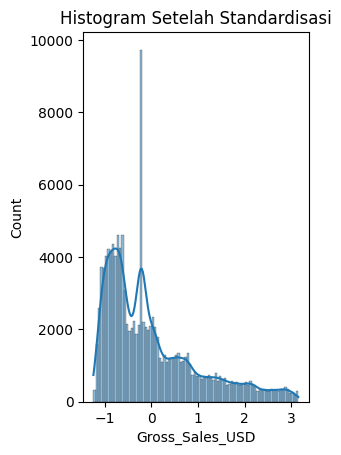

In [17]:
# Histogram Setelah Standardisasi
plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Setelah Standardisasi")

# Menangani Duplikasi Data

In [18]:
# Mengidentifikasi baris duplikat
duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [Customer_Age, Quantity, Unit_Price_USD, Gross_Sales_USD, Discount_Percentage, Discount_Amount_USD, Net_Sales_USD, Tax_Rate_Percentage, Tax_USD, Shipping_Cost_USD, Total_Order_Value_USD, Delivery_Days, Customer_Rating, Order_Profit_USD, Profit_Margin_Percentage, Order_ID, Order_Date, Order_Time, Customer_ID, Customer_Name, Customer_Gender, Customer_Country, Customer_Continent, Customer_City, Customer_Region, Customer_Segment, Product_ID, SKU, Product_Name, Product_Category, Product_Subcategory, Brand, Payment_Method, Payment_Status, Order_Status, Shipping_Method, Return_Status, Marketing_Channel, Device_Type, Review_Sentiment, Sales_Region, Warehouse, Supplier]
Index: []

[0 rows x 43 columns]


In [19]:
# Menghapus baris duplikat
df = df.drop_duplicates()

print("DataFrame setelah menghapus duplikat:")
print(df)

DataFrame setelah menghapus duplikat:
        Customer_Age  Quantity  Unit_Price_USD  Gross_Sales_USD  \
1           1.104332 -0.897896        0.886235        -0.142697   
2          -1.400787 -0.897896        2.474043         0.684860   
3          -1.639370 -0.897896       -0.111735        -0.662833   
4          -1.639370 -0.016432       -0.293307        -0.239936   
5          -1.639370 -0.016432       -0.218057        -0.215010   
...              ...       ...             ...              ...   
199994      1.462206 -0.897896       -0.285471        -0.753384   
199995     -0.088582 -0.016432        1.843811         1.987772   
199996     -1.579724  0.865031       -0.217381         0.396310   
199997     -1.579724 -0.897896       -0.273717        -0.747258   
199999      0.686812 -0.016432       -1.142939        -1.125584   

        Discount_Percentage  Discount_Amount_USD  Net_Sales_USD  \
1                 -0.330298            -0.243235      -0.073459   
2                 -0.03

# Mengonversi Tipe Data

In [20]:
category_features = df.select_dtypes(include=['object']).columns
df[category_features]

,Order_ID,Order_Date,Order_Time,Customer_ID,Customer_Name,Customer_Gender,Customer_Country,Customer_Continent,Customer_City,Customer_Region,...,Payment_Status,Order_Status,Shipping_Method,Return_Status,Marketing_Channel,Device_Type,Review_Sentiment,Sales_Region,Warehouse,Supplier
1,ORD-178205,2026-02-19,10:10:49,CUST-000001,Mateo Park,Male,Canada,North America,Vancouver,British Columbia,...,Paid,Processing,Express,No Return,Email Marketing,Desktop,Negative,North America,London,International Retail Distribution
2,ORD-057651,2026-07-19,11:44:02,CUST-000002,Nina Wong,Female,New Zealand,Oceania,Auckland,Auckland,...,Paid,Delivered,Standard,No Return,Social Media,Tablet,Neutral,Asia Pacific,Toronto,Premium Electronics Supply
3,ORD-124661,2026-08-26,18:13:21,CUST-000003,Aisha Moore,Female,Kenya,Africa,Eldoret,Mombasa,...,Paid,Delivered,Economy,No Return,Social Media,Tablet,Positive,Africa,Dubai,Premium Electronics Supply
4,ORD-162453,2026-09-08,10:34:46,CUST-000003,Aisha Moore,Female,Kenya,Africa,Eldoret,Mombasa,...,Pending,Processing,Express,No Return,Organic Search,Desktop,Neutral,Africa,Toronto,Global Home Supplies
5,ORD-017387,2026-09-25,06:19:06,CUST-000003,Aisha Moore,Female,Kenya,Africa,Eldoret,Mombasa,...,Pending,Delivered,Economy,No Return,Paid Search,Tablet,Positive,Africa,Hong Kong,Global Home Supplies
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
199994,ORD-136852,2026-12-08,08:22:25,CUST-074997,Benjamin Kumar 74996,Male,Argentina,South America,Mendoza,Mendoza,...,Paid,Delivered,Standard,No Return,Email Marketing,Mobile,Positive,Latin America,Mumbai,Quality Goods International
199995,ORD-122357,2026-07-05,19:25:22,CUST-074998,Liam Garcia 74997,Female,Portugal,Europe,Lisbon,Coimbra,...,Paid,Delivered,Standard,No Return,Referral,Mobile,Positive,Europe,Amsterdam,Asia Consumer Goods Ltd
199996,ORD-044258,2026-06-07,10:06:53,CUST-074999,Sarah Ali 74998,Female,Israel,Asia,Tel Aviv,Haifa,...,Paid,Delivered,Express,No Return,Influencer Marketing,Mobile,Neutral,Asia Pacific,Frankfurt,Global Tech Distribution
199997,ORD-163851,2026-06-18,17:50:18,CUST-074999,Sarah Ali 74998,Female,Israel,Asia,Tel Aviv,Haifa,...,Pending,Delivered,Standard,No Return,Affiliate,Desktop,Positive,Asia Pacific,Amsterdam,Quality Goods International


# One Hot Encoding

In [21]:
from sklearn.preprocessing import OneHotEncoder

category_selected = [
    col for col in category_features
    if df[col].nunique() <= 20
]

encoder = OneHotEncoder(
    handle_unknown='ignore',
    sparse_output=True,
    dtype='int8'
)

encoded_data = encoder.fit_transform(
    df[category_selected].astype(str)
)

print("Encoding berhasil!")
print("Jumlah baris dan kolom:", encoded_data.shape)

Encoding berhasil!
Jumlah baris dan kolom: (124933, 102)


In [22]:
# Menampilkan hasil One Hot Encoding
print(encoded_data[:5].toarray())

[[0 1 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0
  0 0 0 0 0 0 0 1 0 1 0 0 0 0 1 0 0 0 1 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 1 0
  0 1 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0]
 [1 0 0 0 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 0 0 1 0 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 1 1 0 0 0 0 0 0 0 0 0 0 1 0 0
  1 0 1 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 1 0 0 0]
 [1 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
  0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0
  1 0 0 1 1 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0]
 [1 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0
  0 0 0 1 0 0 0 0 0 0 1 0 0 0 1 0 0 0 1 0 0 0 1 0 0 0 0 0 0 0 1 0 0 0 1 0
  0 0 1 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 0 0 0 0 0 0]
 [1 0 0 0 1 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0
  0 0 0 0 1 0 0 0 0 0 1 0 0 1 0 0 0 1 0 0 0 0 1 0 0 0 0 0 0 0 0 1 0 0 0 0
  1 0 0 

In [23]:
# Menghitung jumlah dan persentase missing values
missing_values = df.isnull().sum()

missing_percentage = (
    missing_values / len(df)
) * 100

missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(
    by='Missing Values',
    ascending=False
)

# Menampilkan kolom yang memiliki missing values
missing_data = missing_data[
    missing_data['Missing Values'] > 0
]

display(missing_data)

,Missing Values,Percentage


In [24]:
import pandas as pd

df_lencoder = pd.DataFrame.sparse.from_spmatrix(
    encoded_data,
    columns=encoder.get_feature_names_out(category_selected)
)

print("Data berhasil diubah menjadi DataFrame!")
print("Ukuran data:", df_lencoder.shape)

display(df_lencoder.head())

Data berhasil diubah menjadi DataFrame!
Ukuran data: (124933, 102)


,Customer_Gender_Female,Customer_Gender_Male,Customer_Gender_Non-binary,Customer_Gender_Prefer not to say,Customer_Continent_Africa,Customer_Continent_Asia,Customer_Continent_Europe,Customer_Continent_North America,Customer_Continent_Oceania,Customer_Continent_South America,...,Warehouse_Toronto,Supplier_Asia Consumer Goods Ltd,Supplier_Direct Import Source,Supplier_Global Home Supplies,Supplier_Global Tech Distribution,Supplier_International Retail Distribution,Supplier_Premium Electronics Supply,Supplier_Quality Goods International,Supplier_Smart Products Distribution,Supplier_Urban Fashion Wholesale
0,0,1,0,0,0,0,0,1,0,0,...,0,0,0,0,0,1,0,0,0,0
1,1,0,0,0,0,0,0,0,1,0,...,1,0,0,0,0,0,1,0,0,0
2,1,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,1,0,0,0
3,1,0,0,0,1,0,0,0,0,0,...,1,0,0,1,0,0,0,0,0,0
4,1,0,0,0,1,0,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0




In [25]:
import matplotlib.pyplot as plt
import math

n_cols = 4
n_rows = math.ceil(len(df_lencoder.columns) / n_cols)

fig, axes = plt.subplots(
    n_rows,
    n_cols,
    figsize=(16, 4 * n_rows)
)

axes = axes.flatten()

for i, column in enumerate(df_lencoder.columns):
    df_lencoder[column].hist(
        ax=axes[i],
        bins=20,
        edgecolor="black"
    )
    axes[i].set_title(column)
    axes[i].set_xlabel("Value")
    axes[i].set_ylabel("Frequency")

for j in range(len(df_lencoder.columns), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

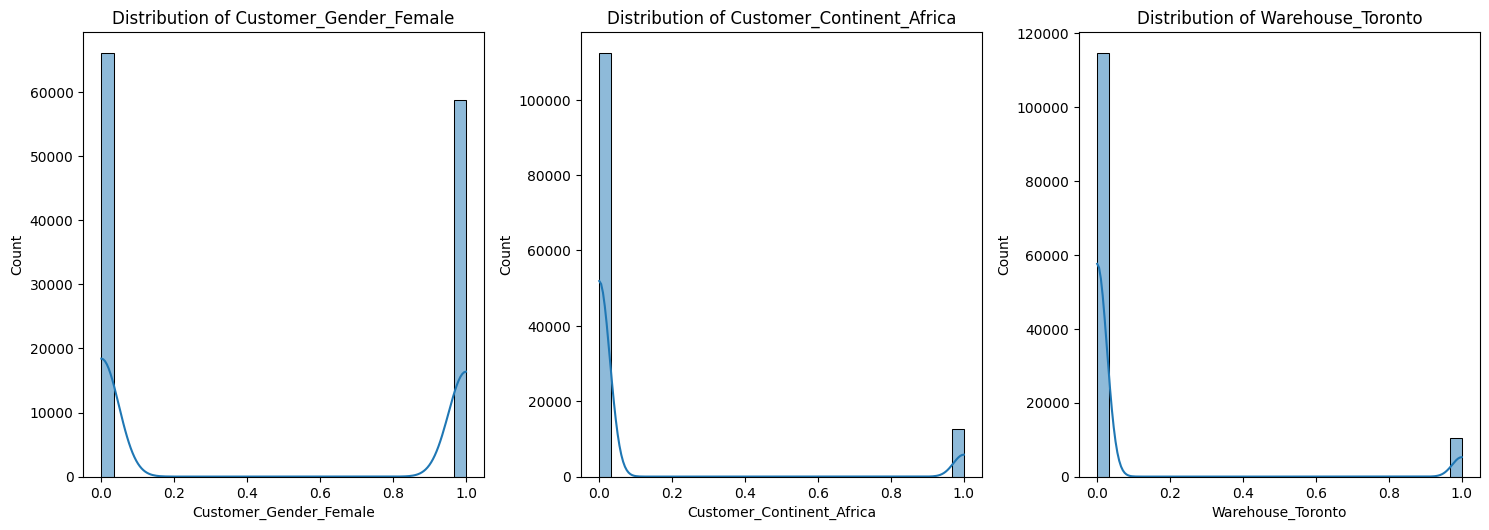

In [28]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Definisi kolom yang ingin diplot (sesuaikan nama kolomnya dengan dataframe Anda)
columns_to_plot = ['Customer_Gender_Female', 'Customer_Continent_Africa', 'Warehouse_Toronto']

plt.figure(figsize=(15, 10))

# Hanya mengambil kolom yang benar-benar ada di dalam df_lencoder
valid_columns = [col for col in columns_to_plot if col in df_lencoder.columns]

for i, column in enumerate(valid_columns, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df_lencoder[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

Menggunakan kolom target: Customer_Gender_Female


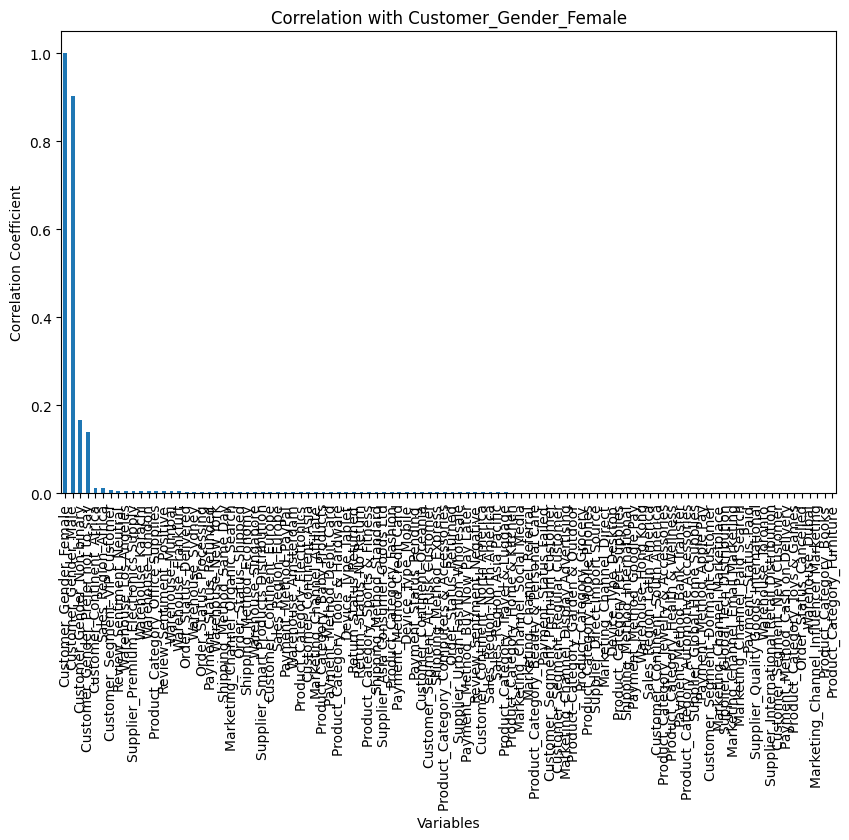

In [34]:
# Otomatis mengambil kolom pertama yang ada di dataframe sebagai target
target_col = df_lencoder.columns[0]
print(f"Menggunakan kolom target: {target_col}")

target_corr = df_lencoder.corr()[target_col]

# (Opsional) Mengurutkan hasil korelasi berdasarkan korelasi
target_corr_sorted = target_corr.abs().sort_values(ascending=False)

plt.figure(figsize=(10, 6))
target_corr_sorted.plot(kind='bar')
plt.title(f'Correlation with {target_col}')
plt.xlabel('Variables')
plt.ylabel('Correlation Coefficient')
plt.show()

# Data Splitting

In [35]:
import sklearn

In [37]:
# Memisahkan fitur (X) dan target (y) secara otomatis
target_kolom = df_lencoder.columns[0]  # Mengambil kolom pertama sebagai target

X = df_lencoder.drop(columns=[target_kolom])
y = df_lencoder[target_kolom]

print("Berhasil memisahkan X dan y dengan target:", target_kolom)

Berhasil memisahkan X dan y dengan target: Customer_Gender_Female


In [38]:
from sklearn.model_selection import train_test_split

# membagi dataset menjadi training dan testing 
x_train, x_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

In [39]:
# menghitung panjang/jumlah data 
print("Jumlah data: ",len(X))
# menghitung panjang/jumlah data pada x_train
print("Jumlah data latih: ",len(x_train))
# menghitung panjang/jumlah data pada x_test
print("Jumlah data test: ",len(x_test))

Jumlah data:  124933
Jumlah data latih:  99946
Jumlah data test:  24987


# Konversi Pandas Dataframe

In [41]:
import pandas as pd

# Ganti 'ecommerce_orders_transactions_2026.csv'
df = pd.read_csv('ecommerce_orders_transactions_2026.csv')
df.head()

,Order_ID,Order_Date,Order_Time,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Customer_Country,Customer_Continent,Customer_City,...,Review_Sentiment,Is_Repeat_Customer,Sales_Region,Warehouse,Supplier,Order_Profit_USD,Profit_Margin_Percentage,Is_Bestseller_Product,Is_New_Customer,Is_First_Order
0,ORD-105927,2026-02-10,11:34:55,CUST-000001,Mateo Park,65,Male,Canada,North America,Vancouver,...,Neutral,False,North America,Frankfurt,Asia Consumer Goods Ltd,-51.34,-46.73,False,False,True
1,ORD-178205,2026-02-19,10:10:49,CUST-000001,Mateo Park,65,Male,Canada,North America,Vancouver,...,Negative,True,North America,London,International Retail Distribution,24.30,16.34,False,False,False
2,ORD-057651,2026-07-19,11:44:02,CUST-000002,Nina Wong,23,Female,New Zealand,Oceania,Auckland,...,Neutral,False,Asia Pacific,Toronto,Premium Electronics Supply,64.77,25.86,False,False,True
3,ORD-124661,2026-08-26,18:13:21,CUST-000003,Aisha Moore,19,Female,Kenya,Africa,Eldoret,...,Positive,False,Africa,Dubai,Premium Electronics Supply,9.29,12.57,False,False,True
4,ORD-162453,2026-09-08,10:34:46,CUST-000003,Aisha Moore,19,Female,Kenya,Africa,Eldoret,...,Neutral,True,Africa,Toronto,Global Home Supplies,-15.16,-13.75,False,False,False


In [42]:
import pandas as pd

In [44]:
df = pd.read_csv('ecommerce_orders_transactions_2026.csv')
df.head()

,Order_ID,Order_Date,Order_Time,Customer_ID,Customer_Name,Customer_Age,Customer_Gender,Customer_Country,Customer_Continent,Customer_City,...,Review_Sentiment,Is_Repeat_Customer,Sales_Region,Warehouse,Supplier,Order_Profit_USD,Profit_Margin_Percentage,Is_Bestseller_Product,Is_New_Customer,Is_First_Order
0,ORD-105927,2026-02-10,11:34:55,CUST-000001,Mateo Park,65,Male,Canada,North America,Vancouver,...,Neutral,False,North America,Frankfurt,Asia Consumer Goods Ltd,-51.34,-46.73,False,False,True
1,ORD-178205,2026-02-19,10:10:49,CUST-000001,Mateo Park,65,Male,Canada,North America,Vancouver,...,Negative,True,North America,London,International Retail Distribution,24.30,16.34,False,False,False
2,ORD-057651,2026-07-19,11:44:02,CUST-000002,Nina Wong,23,Female,New Zealand,Oceania,Auckland,...,Neutral,False,Asia Pacific,Toronto,Premium Electronics Supply,64.77,25.86,False,False,True
3,ORD-124661,2026-08-26,18:13:21,CUST-000003,Aisha Moore,19,Female,Kenya,Africa,Eldoret,...,Positive,False,Africa,Dubai,Premium Electronics Supply,9.29,12.57,False,False,True
4,ORD-162453,2026-09-08,10:34:46,CUST-000003,Aisha Moore,19,Female,Kenya,Africa,Eldoret,...,Neutral,True,Africa,Toronto,Global Home Supplies,-15.16,-13.75,False,False,False


# SKLearn Train Test Split

In [2]:
import sklearn
from sklearn import model_selection

In [4]:
import sklearn
from sklearn import datasets

In [6]:
# Memuat data iris terlebih dahulu
iris = datasets.load_iris()

# Pisahkan atribut dan label pada iris dataset
x = iris.data
y = iris.target

print("Berhasil! Ukuran data x:", x.shape)

Berhasil! Ukuran data x: (150, 4)


In [7]:
from sklearn.model_selection import train_test_split

# membagi dataset menjadi training dan testing 
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=1)

In [8]:
# menghitung panjang/jumlah data pada x_test
len(x_test)

30

# KLearn Cross Validation Split

In [10]:
import sklearn
from sklearn import datasets

# Load iris dataset
iris = datasets.load_iris()

In [11]:
# mendefinisikan atribut dan label pada dataset
x=iris.data
y=iris.target

In [13]:
from sklearn import tree

# membuat model dengan decision tree classifier
clf = tree.DecisionTreeClassifier()

In [15]:
from sklearn.model_selection import cross_val_score

# mengevaluasi performa model dengan cross_val_score
scores = cross_val_score(clf, x, y, cv=5)
print("Scores:", scores)

Scores: [0.96666667 0.96666667 0.9        0.93333333 1.        ]
